# Лабораторная №1. Предсказание качества вина

**Задача:** по характеристикам вина (`X`) предсказать оценку `quality` (`y`).

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
DATA_DIR = Path('data') if Path('data/winequality-red.csv').exists() else Path('regression/data')
sns.set_theme(style='whitegrid')

## 1. Загрузка данных

Одна строка — запись о вине. Входные признаки: кислотности, лимонная кислота, сахар, хлориды, свободный и общий диоксид серы, плотность, pH, сульфаты, алкоголь и добавленный тип вина. `quality` — оценка экспертов, которую предсказываем.

Проверяем размер, типы столбцов, пропуски и повторы. В CSV разделитель — `;`.

In [4]:
red = pd.read_csv(DATA_DIR / 'winequality-red.csv', sep=';')
white = pd.read_csv(DATA_DIR / 'winequality-white.csv', sep=';')
raw_data = pd.concat([red.assign(is_red=1), white.assign(is_red=0)], ignore_index=True)

print('Размер:', raw_data.shape)
display(raw_data.head())
display(pd.DataFrame({'Тип': raw_data.dtypes.astype(str), 'Пропуски': raw_data.isna().sum()}))
print('Точные повторы:', raw_data.duplicated().sum())
data = raw_data.drop_duplicates().reset_index(drop=True)

Размер: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


,Тип,Пропуски
fixed acidity,float64,0
volatile acidity,float64,0
citric acid,float64,0
residual sugar,float64,0
chlorides,float64,0
free sulfur dioxide,float64,0
total sulfur dioxide,float64,0
density,float64,0
pH,float64,0
sulphates,float64,0


Точные повторы: 1177


**Вывод:** 6 497 строк, 1 177 точных повторов. После их удаления остаётся 5 320 записей. Все признаки числовые, пропусков нет, заполнять их не требуется. Исходные CSV не меняем. Оценка качества далее относится к уникальным записям.

## 2. Разделение на обучение и проверку

Около **80%** данных оставляем для обучения, **20%** — для теста: это даёт достаточно обучающих примеров и около тысячи для проверки. Фиксируем `random_state=42`.

Здесь сохраняем прежнее групповое разбиение: одинаковые характеристики вина, даже с разными оценками, помещаем в одну часть. Иначе модель могла бы увидеть тот же объект при обучении и проверке.

Test используем только в конце. Выбираем модель по кросс-валидации внутри train. Многократный подбор по test подстроил бы решение под эту проверку и сделал результат слишком оптимистичным.

In [5]:
X = data.drop(columns='quality')
y = data['quality']
# Одинаковым наборам признаков присваиваем один номер группы.
groups = X.groupby(list(X.columns), sort=False).ngroup()
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(split.split(X, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]
train_data = X_train.assign(quality=y_train)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (4256, 12) | Test: (1064, 12)


## 3. Исследование train

Смотрим на разброс характеристик, частоту оценок и корреляции с `quality`. Корреляция показывает линейную связь: положительная — величины чаще растут вместе, отрицательная — изменяются в разные стороны.

,count,mean,std,min,25%,50%,75%,max
fixed acidity,4256.0,7.20,1.32,3.80,6.40,6.90,7.70,15.90
volatile acidity,4256.0,0.34,0.17,0.08,0.23,0.30,0.41,1.58
citric acid,4256.0,0.32,0.15,0.00,0.24,0.31,0.40,1.66
residual sugar,4256.0,5.07,4.53,0.60,1.80,2.80,7.50,65.80
chlorides,4256.0,0.06,0.03,0.01,0.04,0.05,0.07,0.61
free sulfur dioxide,4256.0,30.23,18.08,1.00,16.00,28.00,41.00,289.00
total sulfur dioxide,4256.0,114.77,56.88,6.00,75.00,117.00,155.00,440.00
density,4256.0,0.99,0.00,0.99,0.99,0.99,1.00,1.04
pH,4256.0,3.22,0.16,2.72,3.11,3.21,3.33,4.01
sulphates,4256.0,0.53,0.14,0.22,0.43,0.51,0.60,1.98


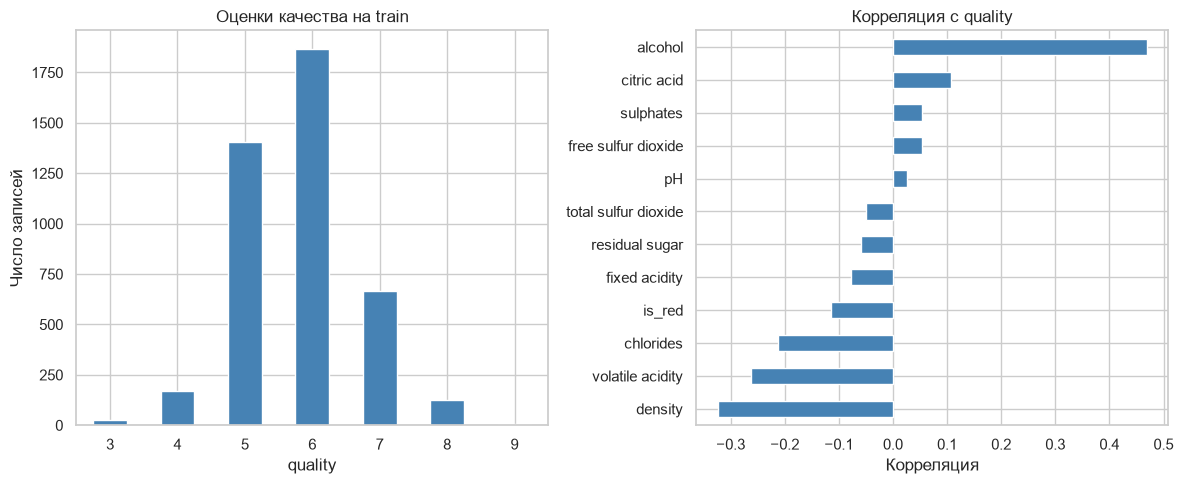

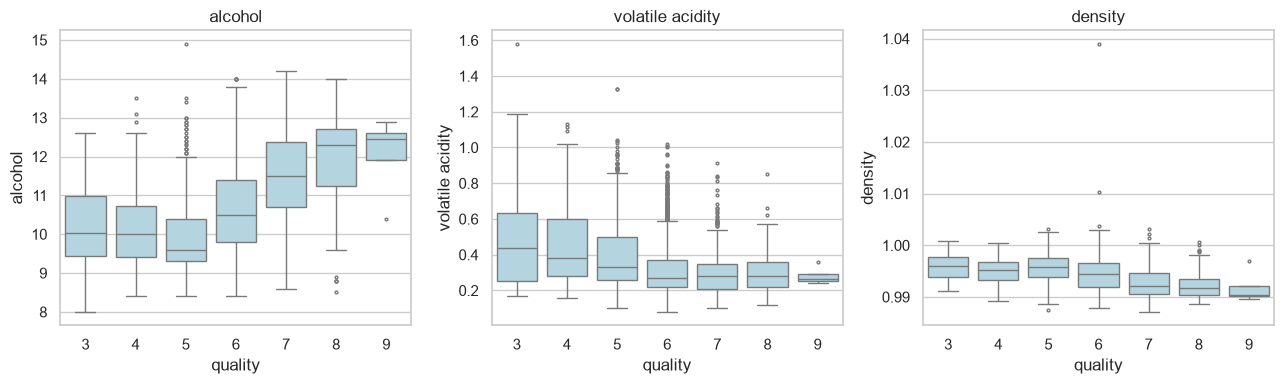

In [6]:
display(train_data.describe().T.round(2))
quality_counts = y_train.value_counts().sort_index()
correlations = X_train.corrwith(y_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
quality_counts.plot.bar(ax=axes[0], rot=0, color='steelblue')
axes[0].set(title='Оценки качества на train', xlabel='quality', ylabel='Число записей')
correlations.sort_values().plot.barh(ax=axes[1], color='steelblue')
axes[1].set(title='Корреляция с quality', xlabel='Корреляция')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, feature in zip(axes, ['alcohol', 'volatile acidity', 'density']):
    sns.boxplot(data=train_data, x='quality', y=feature, ax=ax, color='lightblue', fliersize=2)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

**Выводы:** оценки 5 и 6 составляют около 77% train. Оценки 3 и 9 редкие, поэтому для них модель получает мало примеров. Более высокое содержание алкоголя связано с большей оценкой, летучая кислотность и плотность — с меньшей. Эти признаки сохраняем для моделирования. Распределения соседних оценок перекрываются: по одному признаку точно определить качество нельзя. Слабая корреляция также не исключает полезную нелинейную связь.

## 4. Baseline и метрики

Baseline всем винам предсказывает **среднее `y_train`**. Эта константа минимизирует квадрат ошибки и, следовательно, RMSE.

$$MAE=\frac{1}{n}\sum |y_i-\hat y_i|,\qquad
RMSE=\sqrt{\frac{1}{n}\sum (y_i-\hat y_i)^2}.$$

MAE — средняя абсолютная ошибка в баллах качества. RMSE сильнее учитывает большие промахи из-за возведения в квадрат. Например, для ошибок 0, 0, 3 получаем MAE = 1, RMSE ≈ 1.73. Поэтому метрики одной модели могут различаться. Чем меньше обе метрики, тем лучше. Предсказания не округляем.

In [5]:
print('Константа baseline:', round(y_train.mean(), 4))

Константа baseline: 5.7899


## 5. Модели и кросс-валидация

- **Linear Regression** складывает признаки с обученными коэффициентами.
- **Random Forest** усредняет предсказания многих деревьев.
- **Gradient Boosting** последовательно строит деревья, исправляющие ошибки предыдущих.

Линейную модель помещаем в `Pipeline` со `StandardScaler`: коэффициенты разных признаков становятся сопоставимее. Scaler обучается только на train каждого разбиения. Деревьям масштабирование не требуется.

Настройки деревьев сохранены из первой версии, где они выбирались по CV на train. Здесь не повторяем поиск параметров. Делим train на 5 частей: обучаем на четырёх, проверяем на пятой, затем усредняем RMSE. Для защиты от повторов используем `GroupKFold`. Выбираем лучшую модель **до проверки на test**.

In [8]:
models = {
    'Baseline': DummyRegressor(strategy='mean'),
    'Linear Regression': Pipeline([
        ('scaler', StandardScaler()), ('model', LinearRegression())
    ]),
    'Random Forest': RandomForestRegressor(
        n_estimators=400, max_features=0.8, random_state=RANDOM_STATE, n_jobs=1
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=350, learning_rate=0.05, max_depth=3,
        min_samples_leaf=5, random_state=RANDOM_STATE
    ),
}

cv_rmse = {}
for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train, groups=groups_train, cv=GroupKFold(n_splits=5),
        scoring='neg_root_mean_squared_error', n_jobs=2, error_score='raise'
    )
    # sklearn возвращает отрицательную ошибку: меняем знак обратно.
    cv_rmse[name] = -scores.mean()

display(pd.Series(cv_rmse, name='CV RMSE').round(4).to_frame())
best_name = min(cv_rmse, key=cv_rmse.get)
print('Выбрана по CV:', best_name)

,CV RMSE
Baseline,0.8827
Linear Regression,0.7355
Random Forest,0.6959
Gradient Boosting,0.7036


Выбрана по CV: Random Forest


## 6. Итоговое сравнение на одном test

`fit` обучает модель, `predict` возвращает её предсказания. После выбора по CV обучаем каждую модель на всём train и оцениваем на одном test. Также смотрим train RMSE: большой разрыв с test может указывать на переобучение.

In [9]:
rows = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({
        'Модель': name,
        'RMSE': root_mean_squared_error(y_test, pred),
        'MAE': mean_absolute_error(y_test, pred),
        'Train RMSE': root_mean_squared_error(y_train, model.predict(X_train)),
    })

results = pd.DataFrame(rows).set_index('Модель')
display(results.round(4))
print('Лучше baseline:', list(results.index[results.RMSE < results.loc['Baseline', 'RMSE']]))

,RMSE,MAE,Train RMSE
Модель,,,
Baseline,0.8676,0.6942,0.8827
Linear Regression,0.7208,0.5602,0.7328
Random Forest,0.6617,0.5092,0.2563
Gradient Boosting,0.6842,0.5264,0.6153


Лучше baseline: ['Linear Regression', 'Random Forest', 'Gradient Boosting']


**Вывод:** все три модели лучше baseline. Линейная регрессия получает RMSE ≈ 0.721, лес — 0.662, бустинг — 0.684. Деревья умеют учитывать нелинейные зависимости и сочетания характеристик, поэтому здесь превосходят линейную модель.

По CV выбран **Random Forest**. У него заметный разрыв train/test: 0.256 против 0.662. Лес сильно подстраивается под train, но усреднение деревьев помогает на новых данных. Его преимущество над бустингом относится к этим настройкам и этому разбиению. Локальный порог 0.70 выполнен; результат скрытого теста неизвестен.

## 7. Коэффициенты и важность признаков

После стандартизации линейный коэффициент показывает изменение предсказания при росте признака на одно стандартное отклонение train, при фиксированных остальных признаках. Знак показывает направление, модуль — размер вклада внутри модели. Для `is_red` такой шаг не равен переходу 0 → 1.

У деревьев `feature_importances_` показывает вклад признака в уменьшение ошибки при разбиениях. Знак влияния из этих значений определить нельзя.

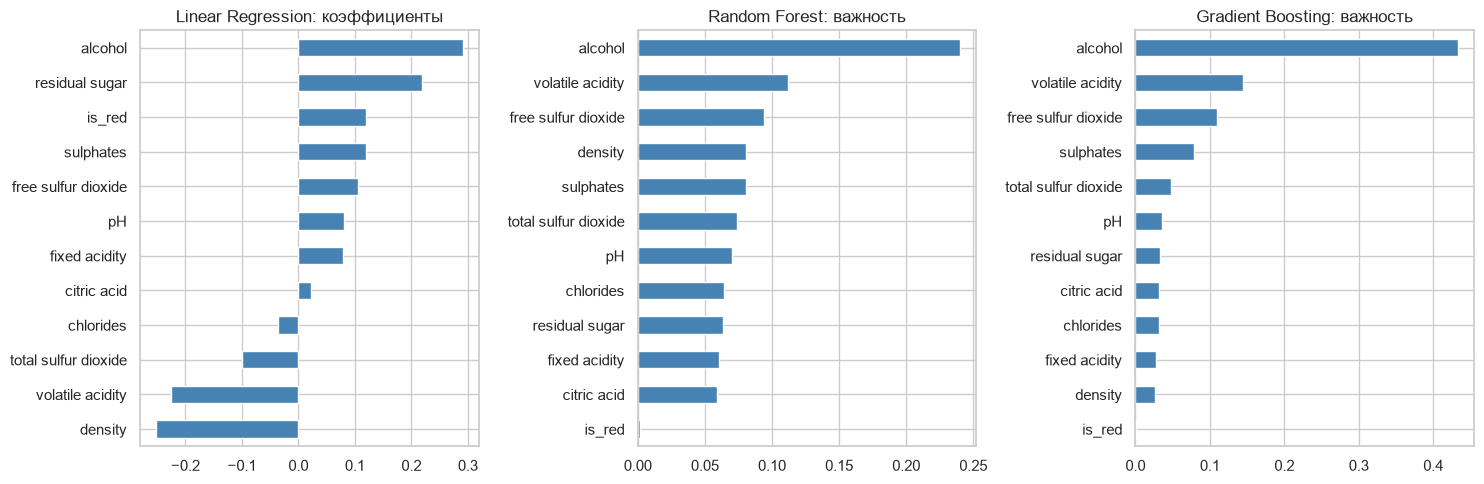

,Корреляция,|Коэффициент|,RF importance,GB importance
alcohol,0.469,0.292,0.240,0.433
volatile acidity,-0.263,0.225,0.112,0.145
free sulfur dioxide,0.054,0.106,0.094,0.109
density,-0.324,0.253,0.081,0.026
sulphates,0.054,0.120,0.081,0.079
total sulfur dioxide,-0.049,0.100,0.074,0.047
pH,0.025,0.081,0.070,0.036
chlorides,-0.212,0.036,0.064,0.032
residual sugar,-0.060,0.219,0.064,0.033
fixed acidity,-0.077,0.079,0.060,0.028


In [10]:
coef = pd.Series(models['Linear Regression'].named_steps['model'].coef_, index=X_train.columns)
rf_importance = pd.Series(models['Random Forest'].feature_importances_, index=X_train.columns)
gb_importance = pd.Series(models['Gradient Boosting'].feature_importances_, index=X_train.columns)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, values, title in zip(axes, [coef, rf_importance, gb_importance],
                             ['Linear Regression: коэффициенты', 'Random Forest: важность', 'Gradient Boosting: важность']):
    values.sort_values().plot.barh(ax=ax, color='steelblue')
    ax.set_title(title)
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    'Корреляция': correlations, '|Коэффициент|': coef.abs(),
    'RF importance': rf_importance, 'GB importance': gb_importance
}).sort_values('RF importance', ascending=False).round(3))

**Вывод:** по модулю линейных коэффициентов выделяются alcohol, density и volatile acidity. У леса и бустинга топ-3 одинаков: alcohol, volatile acidity, free sulfur dioxide. Алкоголь и летучая кислотность выделялись также при анализе корреляций.

Различия ожидаемы: коэффициенты и корреляции описывают линейные связи, деревья учитывают более сложные сочетания. Связанные признаки могут делить важность между собой. Важность по разбиениям также может предпочитать признаки с большим числом возможных порогов.

**Важность не доказывает причинность:** связанные признаки и неизвестные условия производства могут объяснять связь с качеством. Нельзя по этим значениям утверждать, что изменение состава обязательно изменит оценку.

## 8. Анализ ошибок лучшей модели

Ошибка = `предсказание − quality`. Положительная ошибка означает завышенную оценку, отрицательная — заниженную. На графике истинных и предсказанных значений диагональ соответствует точному ответу.

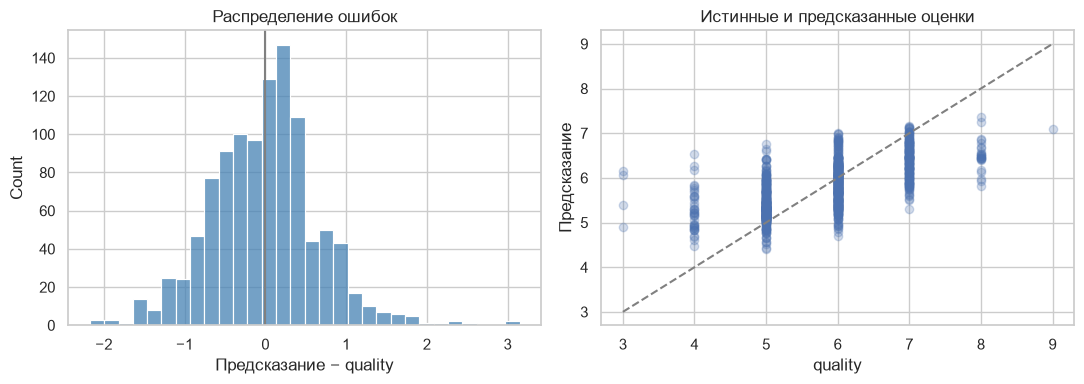

,Train count,Test count,RMSE,MAE,Средняя ошибка
quality,,,,,
3,26,4,2.674,2.626,2.626
4,168,38,1.358,1.274,1.274
5,1404,348,0.560,0.446,0.410
6,1865,458,0.455,0.370,-0.130
7,666,190,0.729,0.626,-0.616
8,123,25,1.532,1.491,-1.491
9,4,1,1.900,1.900,-1.900


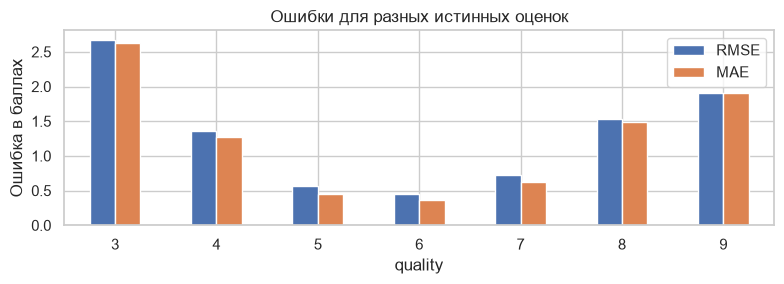

In [11]:
errors = X_test.copy()
errors['quality'] = y_test
errors['prediction'] = predictions[best_name]
errors['error'] = errors.prediction - errors.quality
errors['abs_error'] = errors.error.abs()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(errors.error, bins=30, ax=axes[0], color='steelblue')
axes[0].set(title='Распределение ошибок', xlabel='Предсказание − quality')
axes[0].axvline(0, color='gray')
axes[1].scatter(errors.quality, errors.prediction, alpha=0.25)
axes[1].plot([3, 9], [3, 9], '--', color='gray')
axes[1].set(title='Истинные и предсказанные оценки', xlabel='quality', ylabel='Предсказание')
plt.tight_layout()
plt.show()

group_rows = []
for quality, part in errors.groupby('quality'):
    group_rows.append({
        'quality': quality, 'Train count': int((y_train == quality).sum()), 'Test count': len(part),
        'RMSE': np.sqrt((part.error ** 2).mean()), 'MAE': part.abs_error.mean(),
        'Средняя ошибка': part.error.mean()
    })
quality_errors = pd.DataFrame(group_rows).set_index('quality')
display(quality_errors.round(3))
quality_errors[['RMSE', 'MAE']].plot.bar(figsize=(8, 3), rot=0, ylabel='Ошибка в баллах')
plt.title('Ошибки для разных истинных оценок')
plt.tight_layout()
plt.show()

**Вывод:** модель лучше предсказывает распространённые оценки 5–6. Для редких 3, 8 и 9 ошибка больше: мало обучающих примеров, а общая ошибка в основном определяется частыми оценками. Низкие оценки модель чаще завышает, высокие — занижает. Метрики малых групп неустойчивы, поэтому рядом указано число объектов.

### Три самых крупных промаха

Сопоставим реальные характеристики, истинные и предсказанные оценки. В последнем столбце — сколько примеров такой оценки было в train.

In [10]:
worst = errors.nlargest(3, 'abs_error').copy()
worst['Таких оценок в train'] = worst.quality.map(y_train.value_counts())
display(worst.round(3))

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red,quality,prediction,error,abs_error,Таких оценок в train
4151,6.2,0.23,0.35,0.7,0.051,24.0,111.0,0.992,3.37,0.43,11.0,0,3,6.148,3.148,3.148,26
1729,7.1,0.32,0.32,11.0,0.038,16.0,66.0,0.994,3.24,0.40,11.5,0,3,6.055,3.055,3.055,26
4404,6.5,0.32,0.48,8.0,0.026,18.0,88.0,0.991,3.22,0.79,12.7,0,4,6.532,2.532,2.532,168


**Возможные объяснения:**

- Запись 4151: quality = 3, прогноз ≈ 6.15. Сахара всего 0.7, это необычно низкое значение относительно train. Такой состав и редкая оценка могли затруднить предсказание.
- Запись 1729: quality = 3, прогноз ≈ 6.05. В train только 26 примеров оценки 3. Даже обычные по отдельности характеристики могут сочетаться необычно, а модель смещает ответ к частым оценкам.
- Запись 4404: quality = 4, прогноз ≈ 6.53. Таких оценок в train 168; модель также завышает редкую низкую оценку. Возможны неучтённые свойства вина и различия экспертных оценок.

Это гипотезы, а не установленные причины. По химическим характеристикам нельзя восстановить все особенности вкуса.

## 9. Итог

Baseline RMSE ≈ 0.868. Все обязательные модели его превосходят. Выбранный по CV лес получает **RMSE ≈ 0.662, MAE ≈ 0.509** на локальном test, снижая RMSE примерно на 24% относительно baseline.

Важность признаков согласуется с частью выводов анализа данных, но не доказывает причинность. Общая метрика скрывает крупные ошибки на редких оценках. После анализа test настройки не менялись. На скрытом тесте преподавателя результат не проверен.